David Granados González

This was made mostly using AI and was enhanced by me

Every code cell was runned manually and verified using the references. 



# <b>Challenge 2 · Solution · Transverse-Field Ising Model: Trotter dynamics and SQD</b>

This is my solution to *Simulating Quantum Dynamics: The Transverse-Field Ising Model* (B. Tirado, BasQ Qiskit Fall Fest 2026, with additions by M. Gutiérrez for EnLuz Qiskit Fall Fest 2026). It covers both levels:

* **Beginner:** correlations, Trotter step size, accuracy vs circuit depth, and higher-order formulas.
* **Intermediate:** using SQD to find the ground state, and comparing different starting states to see which one works best.

Everything runs on local simulators (one optional check uses a noisy Aer simulation). I only use the exact answers to check results, never to produce them.

<div class="alert alert-block alert-warning">
<b>Heads up about the original template.</b> The template passes <code>PauliEvolutionGate</code> straight to <code>StatevectorEstimator</code>. The simulator then uses the gate's exact matrix and ignores the <code>LieTrotter</code> setting, so the "Trotter" curve in the template is actually the exact result and its error plot is basically zero. Section 1 shows this and fixes it by simulating the real gates. Everything after that uses real gate-level circuits.
</div>

## Contents
0. [Setup](#setup)
1. [Fixing the template](#fix)
2. **Beginner**
   * 2.1 [Correlations and the light cone](#corr)
   * 2.2 [Trotter step size](#dt)
   * 2.3 [Accuracy vs depth](#depth)
   * 2.4 [Higher order, and the best depth with noise](#higher)
3. **Intermediate: SQD**
   * 3.1 [How SQD works](#sqd)
   * 3.2 [Starting point: GHZ](#ghz)
   * 3.3 [Comparing starting states at the critical point](#zoo)
   * 3.4 [It depends on the phase](#phase)
   * 3.5 [A systematic way to choose the starting state](#systematic)
   * 3.6 [What about noise?](#noise)
4. [Conclusions](#conclusions)

## 0. Setup <a id="setup"></a>
I used `qiskit 2.5`, `qiskit-aer 0.17` and `qiskit-addon-sqd 0.14`, plus `scipy`, `numpy`, `matplotlib` and `pandas`.

In [7]:
%pip install qiskit qiskit-aer qiskit-addon-sqd scipy pandas matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


In [8]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import expm
from scipy.sparse.linalg import eigsh, expm_multiply
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_addon_sqd.qubit import project_operator_to_subspace

warnings.filterwarnings("ignore", category=Warning, module="scipy")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
SEED = 2026
rng = np.random.default_rng(SEED)

In [9]:
# Hamiltonian and observables (same conventions as the template)
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    # H = -J sum Z_i Z_{i+1} - h sum X_i, open chain
    terms = [("ZZ", [i, i + 1], -J) for i in range(num_qubits - 1)]
    terms += [("X", [i], -h) for i in range(num_qubits)]
    return SparsePauliOp.from_sparse_list(terms, num_qubits)

def magnetization_op(num_qubits):
    return SparsePauliOp.from_sparse_list([("Z", [i], 1.0 / num_qubits) for i in range(num_qubits)], num_qubits)

def zz_op(n, i, j):
    return SparsePauliOp.from_sparse_list([("ZZ", [i, j], 1.0)], n)

def z_op(n, i):
    return SparsePauliOp.from_sparse_list([("Z", [i], 1.0)], n)

# Trotter circuits built gate by gate
# exp(+i J dt ZZ) = RZZ(-2 J dt) and exp(+i h dt X) = RX(-2 h dt)
# ZZ gates go on even bonds first, then odd bonds, so the layer has depth 2
def zz_layer(qc, coeff):          # exp(+i coeff * sum ZZ)
    n = qc.num_qubits
    for start in (0, 1):
        for i in range(start, n - 1, 2):
            qc.rzz(-2 * coeff, i, i + 1)

def x_layer(qc, coeff):           # exp(+i coeff * sum X)
    qc.rx(-2 * coeff, range(qc.num_qubits))

def suzuki_layers(order, dt, J, h):
    # One step of the Suzuki formula, as a list of (layer type, coefficient)
    # Order 2: half X, full ZZ, half X (splitting the cheap X layer, not ZZ)
    # Higher orders are built from lower ones: S_2k(dt) = S_{2k-2}(p dt)^2 S_{2k-2}((1-4p) dt) S_{2k-2}(p dt)^2
    if order == 2:
        return [("x", h * dt / 2), ("zz", J * dt), ("x", h * dt / 2)]
    p = 1.0 / (4.0 - 4.0 ** (1.0 / (order - 1)))
    inner = lambda s: suzuki_layers(order - 2, s, J, h)
    return inner(p * dt) * 2 + inner((1 - 4 * p) * dt) + inner(p * dt) * 2

def merge_layers(layers):
    merged = []
    for kind, c in layers:                      # merge neighbouring layers of the same type
        if merged and merged[-1][0] == kind:
            merged[-1] = (kind, merged[-1][1] + c)
        else:
            merged.append((kind, c))
    return merged

def trotter_circuit(n, dt, steps, order=1, J=1.0, h=1.0, initial=None):
    # Start from `initial` (|0..0> by default) and apply `steps` Trotter steps of size dt
    qc = QuantumCircuit(n) if initial is None else initial.copy()
    if order == 1:
        for _ in range(steps):
            zz_layer(qc, J * dt)
            x_layer(qc, h * dt)
        return qc
    for kind, c in merge_layers(suzuki_layers(order, dt, J, h) * steps):
        (zz_layer if kind == "zz" else x_layer)(qc, c)
    return qc

def exact_states(H, psi0, times):
    # Exact state at each time in `times`
    return expm_multiply(-1j * H.to_matrix(sparse=True), psi0,
                         start=times[0], stop=times[-1], num=len(times), endpoint=True)

print("helpers ready")

helpers ready


## 1. Fixing the template <a id="fix"></a>

Same setup as the template (N=4, J=h=1, dt=0.2, 30 steps), run three ways:

1. **The template as written:** `PauliEvolutionGate` with `LieTrotter`, sent straight to the estimator.
2. **The template, decomposed:** the same circuit after `.decompose(reps=3)`, so the simulator sees the actual RZZ and RX gates.
3. **My own builder**, `trotter_circuit(...)`, which writes out the gates directly.

max |template   - exact| = 1.0505485370515544e-14
max |decomposed - exact| = 0.0714293741177881
max |ours       - decomposed| = 2.3314683517128287e-15
gate counts of one decomposed step: {'cx': 6, 'u': 4, 'p': 3, 'barrier': 1}


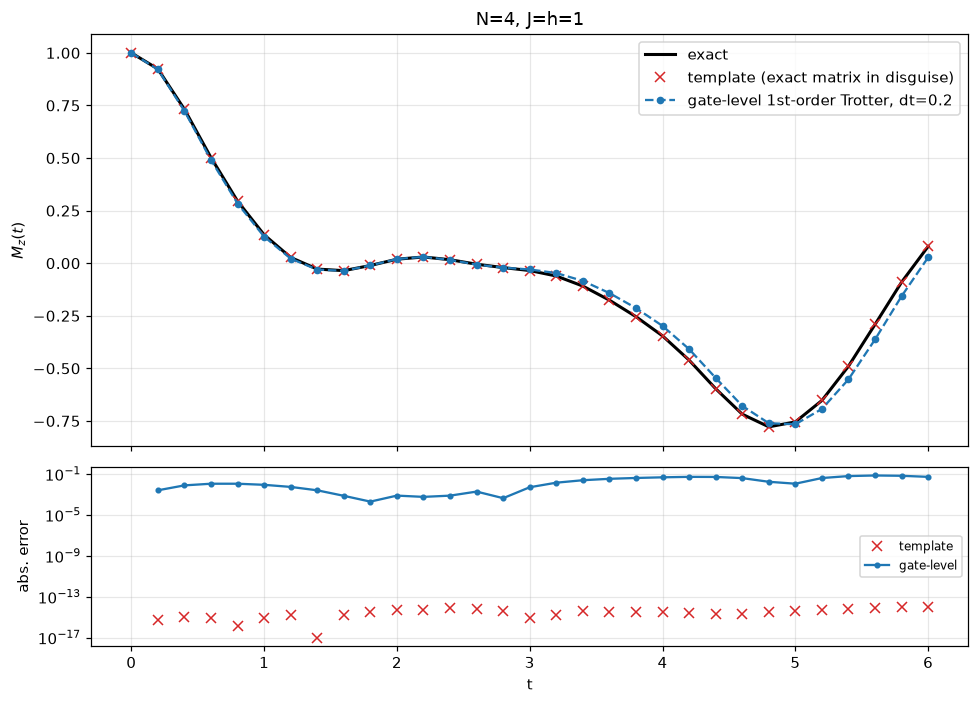

In [10]:
n4, J, h, dt, max_steps = 4, 1.0, 1.0, 0.2, 30
H4, Mz4 = tfim_hamiltonian(n4, J, h), magnetization_op(n4)
times4 = dt * np.arange(max_steps + 1)
estimator = StatevectorEstimator()

def template_circuit(H, n, dt, steps):
    qc = QuantumCircuit(n); qc.barrier()
    for _ in range(steps):
        qc.append(PauliEvolutionGate(H, time=dt, synthesis=LieTrotter(reps=1)), range(n))
    return qc

pubs_template = [(template_circuit(H4, n4, dt, k), Mz4) for k in range(max_steps + 1)]
pubs_decomposed = [(c.decompose(reps=3), o) for c, o in pubs_template]
pubs_ours = [(trotter_circuit(n4, dt, k, 1, J, h), Mz4) for k in range(max_steps + 1)]
mz_template = np.array([float(r.data.evs) for r in estimator.run(pubs_template).result()])
mz_decomposed = np.array([float(r.data.evs) for r in estimator.run(pubs_decomposed).result()])
mz_ours = np.array([float(r.data.evs) for r in estimator.run(pubs_ours).result()])

psi0_4 = Statevector.from_label("0" * n4).data
mz_exact4 = np.array([np.real(np.vdot(s, Mz4.to_matrix() @ s)) for s in exact_states(H4, psi0_4, times4)])

print("max |template   - exact| =", np.max(np.abs(mz_template - mz_exact4)))
print("max |decomposed - exact| =", np.max(np.abs(mz_decomposed - mz_exact4)))
print("max |ours       - decomposed| =", np.max(np.abs(mz_ours - mz_decomposed)))
print("gate counts of one decomposed step:", dict(template_circuit(H4, n4, dt, 1).decompose(reps=3).count_ops()))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
a1.plot(times4, mz_exact4, "k-", lw=2, label="exact")
a1.plot(times4, mz_template, "x", color="C3", label="template (exact matrix in disguise)")
a1.plot(times4, mz_decomposed, "o--", ms=4, color="C0", label="gate-level 1st-order Trotter, dt=0.2")
a1.set_ylabel(r"$M_z(t)$"); a1.legend(); a1.set_title("N=4, J=h=1")
a2.semilogy(times4[1:], np.abs(mz_template - mz_exact4)[1:] + 1e-17, "x", color="C3", label="template")
a2.semilogy(times4[1:], np.abs(mz_decomposed - mz_exact4)[1:], "o-", ms=3, color="C0", label="gate-level")
a2.set_xlabel("t"); a2.set_ylabel("abs. error"); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

The template's result matches the exact curve down to rounding error, so it isn't really simulating Trotter at all. Once you decompose the circuit you see the real Trotter error. My builder gives exactly the same numbers as the decomposed circuit, so I use it for the rest of the notebook. It also lets me control the term order and the higher-order formulas.

## 2. Beginner track
### 2.1 Correlations and the light cone <a id="corr"></a>

I start from all spins up, $|0\cdots0\rangle$, on a 14-spin chain with $J=h=1$, and track

$$\langle Z_iZ_j\rangle(t),\qquad C_{ij}(t)=\langle Z_iZ_j\rangle-\langle Z_i\rangle\langle Z_j\rangle .$$

The second one is the "connected" correlation. It subtracts the part that only comes from the magnetization, so what's left is real correlation between the two spins. I fix one site, $i_0=3$, and look at sites $j=i_0+r$ further along the chain.

**What to expect:** the excitations in this model move at most at speed $v_{\max}=2\min(J,h)=2$. They are created in pairs moving in opposite directions, so two sites a distance $r$ apart should start to be correlated around $t\approx r/(2v_{\max})=r/4$. In other words, correlations should spread inside a "light cone" at about 4 sites per unit of time.

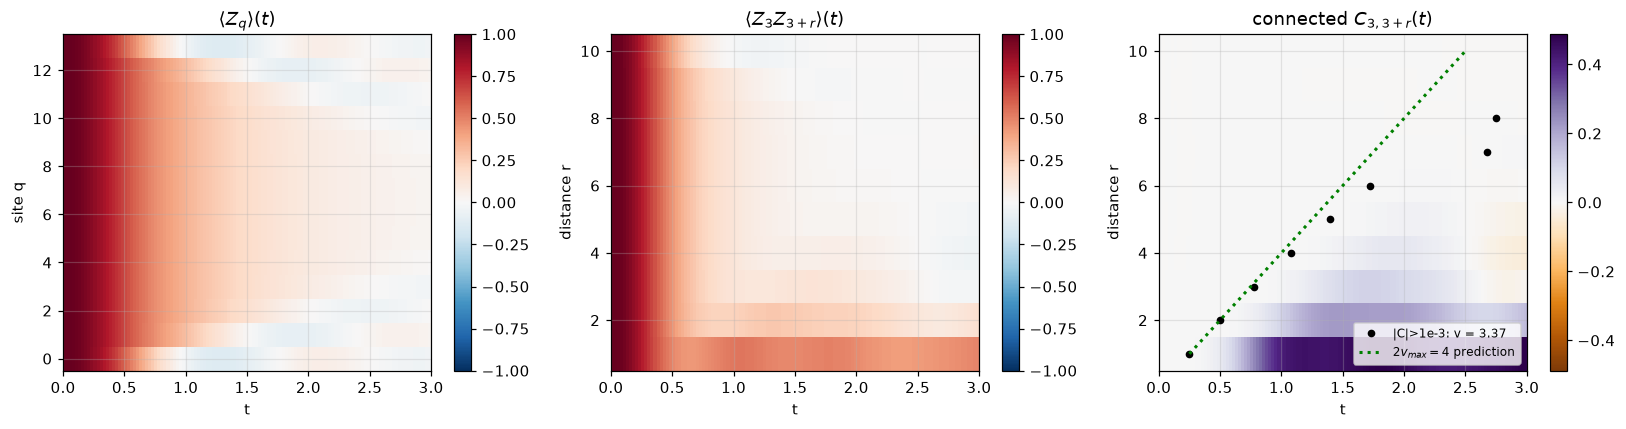

distance r,1,2,3,4,5,6,7,8,9,10
|C| > 0.01,0.375,0.675,1.000,1.350,1.750,NaN,NaN,NaN,NaN,NaN
|C| > 0.003,0.300,0.575,0.875,1.200,1.525,1.925,2.800,NaN,NaN,NaN
|C| > 0.001,0.250,0.500,0.775,1.075,1.400,1.725,2.675,2.750,NaN,NaN
|C| > 0.0003,0.200,0.425,0.700,0.975,1.275,1.575,1.950,2.575,2.7,NaN


,fitted front velocity (sites / time)
|C| > 0.01,2.919708
|C| > 0.003,3.097345
|C| > 0.001,3.373494
|C| > 0.0003,3.608247


peak |C| vs distance: [0.4879 0.2237 0.113  0.0532 0.0251 0.0059 0.0077 0.0012 0.0009 0.    ]


In [11]:
N_c, T_c, n_t = 14, 3.0, 121
times_c = np.linspace(0, T_c, n_t)
H_c = tfim_hamiltonian(N_c, 1.0, 1.0)
psi0_c = Statevector.from_label("0" * N_c).data
states_c = exact_states(H_c, psi0_c, times_c)

# Z-basis quantities only need the probabilities, so compute them directly
idx = np.arange(2 ** N_c)
zvals = np.array([1 - 2 * ((idx >> q) & 1) for q in range(N_c)])          # (N, 2^N)
probs_c = np.abs(states_c) ** 2                                                  # (T, 2^N)
Z_t = probs_c @ zvals.T                                                          # <Z_q>(t)
i0 = 3
rs = np.arange(1, N_c - i0)
ZZ_t = np.array([probs_c @ (zvals[i0] * zvals[i0 + r]) for r in rs]).T          # (T, R)
C_t = ZZ_t - Z_t[:, [i0]] * Z_t[:, i0 + rs]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im = axes[0].imshow(Z_t.T, aspect="auto", origin="lower", extent=[0, T_c, -0.5, N_c - 0.5], cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set(xlabel="t", ylabel="site q", title=r"$\langle Z_q\rangle(t)$"); plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(ZZ_t.T, aspect="auto", origin="lower", extent=[0, T_c, 0.5, rs[-1] + 0.5], cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set(xlabel="t", ylabel="distance r", title=rf"$\langle Z_{{{i0}}}Z_{{{i0}+r}}\rangle(t)$"); plt.colorbar(im, ax=axes[1])
vmax = np.max(np.abs(C_t))
im = axes[2].imshow(C_t.T, aspect="auto", origin="lower", extent=[0, T_c, 0.5, rs[-1] + 0.5], cmap="PuOr", vmin=-vmax, vmax=vmax)
axes[2].set(xlabel="t", ylabel="distance r", title=rf"connected $C_{{{i0},{i0}+r}}(t)$"); plt.colorbar(im, ax=axes[2])

# Light cone: for each distance, the first time |C| goes above a threshold.
# The signal gets weaker with distance, so the answer depends on the threshold.
# Try a few thresholds and see how the speed changes.
def arrival_times(threshold):
    return np.array([times_c[np.argmax(np.abs(C_t[:, k]) > threshold)] if np.any(np.abs(C_t[:, k]) > threshold)
                     else np.nan for k in range(len(rs))])
front = {}
for threshold in (1e-2, 3e-3, 1e-3, 3e-4):
    arr = arrival_times(threshold)
    ok = ~np.isnan(arr) & (rs <= 6)                       # avoid the end of the chain
    front[threshold] = (arr, 1 / np.polyfit(rs[ok], arr[ok], 1)[0])
arr = front[1e-3][0]
axes[2].plot(arr, rs, "k.", ms=8, label=f"|C|>1e-3: v = {front[1e-3][1]:.2f}")
axes[2].plot(rs / 4.0, rs, "g:", lw=2, label=r"$2v_{max}=4$ prediction")
axes[2].legend(fontsize=8, loc="lower right"); axes[2].set_xlim(0, T_c)
plt.tight_layout(); plt.show()
display(pd.DataFrame({f"|C| > {t:g}": a for t, (a, v) in front.items()}, index=pd.Index(rs, name="distance r")).T)
display(pd.Series({f"|C| > {t:g}": v for t, (a, v) in front.items()}, name="fitted front velocity (sites / time)").to_frame())
peak = np.abs(C_t).max(axis=0)
print("peak |C| vs distance:", np.round(peak, 4))

In [12]:
# Check that a real Trotter circuit gets the same correlations (2nd order, dt = 0.1)
dt_c = 0.1
check_times = np.arange(0, T_c + 1e-9, dt_c)
exact_check = exact_states(H_c, psi0_c, check_times)
worst = 0.0
for k, t in enumerate(check_times):
    sv = Statevector(trotter_circuit(N_c, dt_c, k, order=2)).data
    p = np.abs(sv) ** 2; pe = np.abs(exact_check[k]) ** 2
    zz_tr = np.array([p @ (zvals[i0] * zvals[i0 + r]) for r in rs])
    zz_ex = np.array([pe @ (zvals[i0] * zvals[i0 + r]) for r in rs])
    worst = max(worst, np.max(np.abs(zz_tr - zz_ex)))
print(f"2nd-order Trotter (dt={dt_c}): max |<Z_i0 Z_i0+r>_Trotter - exact| over t<={T_c} and all r = {worst:.2e}")

2nd-order Trotter (dt=0.1): max |<Z_i0 Z_i0+r>_Trotter - exact| over t<=3.0 and all r = 1.06e-02


**What the plots show**

* $\langle Z_q\rangle$ drops from +1 and then oscillates. The spins at the ends of the chain behave a bit differently because they only have one neighbour.
* The plain $\langle Z_{i_0}Z_{i_0+r}\rangle$ starts at 1 for every distance, but that's just because all spins start aligned. The connected version is the interesting one: it starts at zero and only becomes nonzero inside a light cone.
* The time it takes for correlations to arrive grows linearly with distance, so information travels at a finite speed.
* The measured speed depends on the threshold you use to say correlations have "arrived", because the signal gets weaker with distance (it roughly halves every site). Lower thresholds give speeds closer to the predicted 4, and it never goes above that.
* In practice this means you need to simulate until roughly $t\approx r/4$ to see correlations at distance $r$, and the chain has to be long enough that the cone hasn't reached the end.
* A 2nd-order Trotter circuit with $\Delta t=0.1$ already gets these correlations right to within about 0.01.

### 2.2 Trotter step size <a id="dt"></a>

I fix the final time at $T=4$ on 8 spins and try different numbers of steps ($\Delta t=T/n$). I look at two kinds of error:

* **Magnetization error:** the biggest difference in $M_z$ from the exact result at any point up to $T$. (Just checking the final time can be misleading, since the error can be zero there by coincidence.)
* **State error:** how far the final quantum state is from the exact one, $\sqrt{1-|\langle\psi_{\text{exact}}|\psi_{\text{Trotter}}\rangle|^2}$.

In theory, an order-$p$ formula has error proportional to $\Delta t^{\,p}$, so on a log-log plot the lines should have slopes 1, 2 and 4.

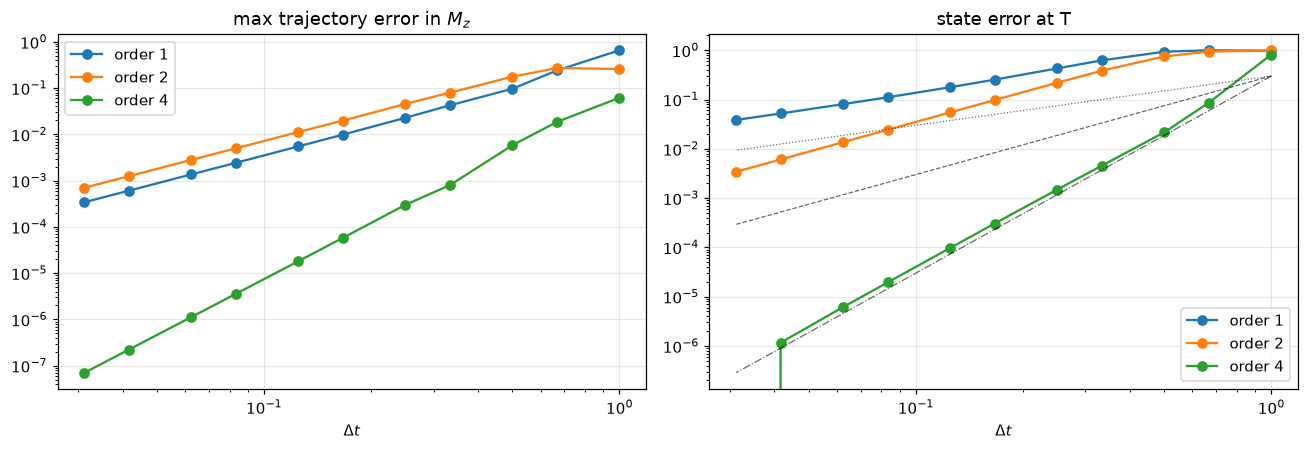

Fitted asymptotic slopes of the state error vs dt: {1: np.float64(1.1), 2: np.float64(2.0), 4: np.float64(4.01)}
Largest dt (from the grid) with trajectory error in M_z below 0.01:


,max dt
order,
1,0.166667
2,0.083333
4,0.500000


In [13]:
N_s, T_s = 8, 4.0
H_s, Mz_s = tfim_hamiltonian(N_s), magnetization_op(N_s)
psi0_s = Statevector.from_label("0" * N_s).data
Mz_diag = np.real(np.diag(Mz_s.to_matrix()))
step_list = [4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128]
orders = [1, 2, 4]

def trajectory_errors(order, steps):
    dtt = T_s / steps
    exact_traj = exact_states(H_s, psi0_s, np.linspace(0, T_s, steps + 1))
    qc = QuantumCircuit(N_s)
    sv = Statevector(qc)
    obs_err = 0.0
    step_circuit = trotter_circuit(N_s, dtt, 1, order)
    for k in range(1, steps + 1):
        sv = sv.evolve(step_circuit)
        obs_err = max(obs_err, abs(np.abs(sv.data) ** 2 @ Mz_diag - np.abs(exact_traj[k]) ** 2 @ Mz_diag))
    state_err = np.sqrt(max(0.0, 1 - abs(np.vdot(exact_traj[-1], sv.data)) ** 2))
    return obs_err, state_err

def gate_cost(order, steps):
    tq = transpile(trotter_circuit(N_s, T_s / steps, steps, order),
                   basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    return tq.count_ops().get("cx", 0), tq.depth()

rows = []
for order in orders:
    for steps in step_list:
        obs_err, state_err = trajectory_errors(order, steps)
        cx, depth = gate_cost(order, steps)
        rows.append(dict(order=order, steps=steps, dt=T_s / steps, obs_err=obs_err,
                         state_err=state_err, cx=cx, depth=depth))
scan = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
fits = {}
for order, color in zip(orders, ["C0", "C1", "C2"]):
    s = scan[scan.order == order]
    for ax, col in zip(axes, ["obs_err", "state_err"]):
        ax.loglog(s.dt, s[col], "o-", color=color, label=f"order {order}")
    asym = s[(s.state_err < 0.3) & (s.state_err > 1e-12)].tail(5)       # small-step region only
    fits[order] = np.polyfit(np.log(asym.dt), np.log(asym.state_err), 1)[0]
for ax, title in zip(axes, ["max trajectory error in $M_z$", "state error at T"]):
    ax.set_xlabel(r"$\Delta t$"); ax.set_title(title); ax.legend()
for k, ls in [(1, ":"), (2, "--"), (4, "-.")]:
    axes[1].loglog(scan.dt.unique(), 0.3 * scan.dt.unique() ** k, "k" + ls, lw=0.8, alpha=0.6)
plt.tight_layout(); plt.show()
print("Fitted asymptotic slopes of the state error vs dt:", {k: round(v, 2) for k, v in fits.items()})

tol = 1e-2
need = scan[scan.obs_err < tol].groupby("order").dt.max()
print(f"Largest dt (from the grid) with trajectory error in M_z below {tol}:")
display(need.rename("max dt").to_frame())

**What I found**

* **State error:** the slopes come out as 1.1, 2.0 and 4.0, just like the theory says. With very big steps everything breaks down.
* **Surprise with the magnetization:** for $M_z$, the 1st-order formula behaves like a 2nd-order one (its error shrinks with $\Delta t^2$), and it's even about 2× better than my 2nd-order circuit. There's a neat reason. With $A=H_{ZZ}$ and $B=H_X$,

  $$\big(e^{-iA\Delta t}e^{-iB\Delta t}\big)^n=e^{-iA\Delta t/2}\Big(e^{-iA\Delta t/2}e^{-iB\Delta t}e^{-iA\Delta t/2}\Big)^n e^{+iA\Delta t/2}.$$

  The starting state is an eigenstate of $A$, so the factor on the right does nothing. The factor on the left only adds phases in the Z basis, so it can't change $M_z$ or $\langle Z_iZ_j\rangle$. For these quantities the 1st-order formula is really a 2nd-order one in disguise, for free.
* **How small does $\Delta t$ need to be?** To keep the $M_z$ error under 1% up to $t=4$: about 0.17 for 1st order, 0.08 for my 2nd order, and 0.5 for 4th order. For an accurate full state (error under 1%), 1st order needs much smaller steps than 0.03, while 4th order is fine at about 0.33.
* Errors in simple observables are much smaller than errors in the full state. So the right step size depends on what you're measuring.

### 2.3 Accuracy vs depth <a id="depth"></a>

Here I measure cost in CNOT gates after transpiling to `{cx, rz, sx, x}` (each RZZ becomes 2 CNOTs):

| formula | ZZ layers per step | CNOTs per step (8 spins) |
|---|---|---|
| 1st order | 1 | 14 |
| 2nd order (split the X layer) | 1 | 14 |
| 4th order | 5 | 70 |

The trick for 2nd order is to split the cheap X layer instead of the ZZ layer, and merge the half-steps between neighbouring steps. Then 2nd order costs exactly the same as 1st order. Qiskit's default `SuzukiTrotter(order=2)` splits the ZZ layer instead, so it costs twice as many CNOTs (see below).

CX per step, Qiskit default SuzukiTrotter(order=2): 28
CX per step, our Strang ordering                 : 14


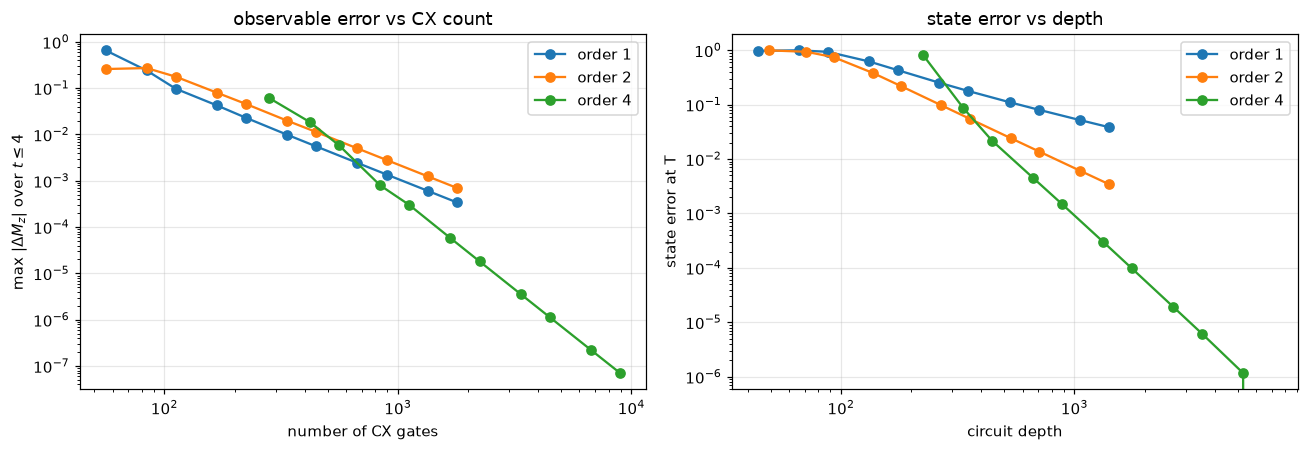

,obs_err < 0.01,obs_err < 0.001,state_err < 0.01,state_err < 0.0001
minimum CX count,,,,
order 1,336,1344,NaN,NaN
order 2,672,1792,1344.0,NaN
order 4,560,840,840.0,2240.0


In [14]:
step_q = QuantumCircuit(N_s)
step_q.append(PauliEvolutionGate(H_s, time=0.1, synthesis=SuzukiTrotter(order=2, reps=1)), range(N_s))
naive = transpile(step_q.decompose(reps=3), basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
print("CX per step, Qiskit default SuzukiTrotter(order=2):", naive.count_ops().get("cx", 0))
print("CX per step, our Strang ordering                 :", gate_cost(2, 1)[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for order, color in zip(orders, ["C0", "C1", "C2"]):
    s = scan[scan.order == order]
    axes[0].loglog(s.cx, s.obs_err, "o-", color=color, label=f"order {order}")
    axes[1].loglog(s.depth, s.state_err, "o-", color=color, label=f"order {order}")
axes[0].set(xlabel="number of CX gates", ylabel=r"max $|\Delta M_z|$ over $t\leq4$", title="observable error vs CX count")
axes[1].set(xlabel="circuit depth", ylabel="state error at T", title="state error vs depth")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

def cheapest(metric, target):
    out = {}
    for order in orders:
        s = scan[(scan.order == order) & (scan[metric] < target)]
        out[f"order {order}"] = int(s.cx.min()) if len(s) else None
    return out
display(pd.DataFrame({f"{m} < {t:g}": cheapest(m, t)
                      for m, t in [("obs_err", 1e-2), ("obs_err", 1e-3), ("state_err", 1e-2), ("state_err", 1e-4)]}
                     ).rename_axis("minimum CX count"))

**What I found**

* **For the full state:** 4th order is the cheapest way to get good accuracy. Getting the state error under 1% takes 840 CNOTs with 4th order, 1,344 with 2nd order, and 1st order doesn't get there even with 1,792.
* **For $M_z$:** because of the hidden 2nd-order behaviour from 2.2, plain 1st order reaches 1% with the fewest CNOTs (336). For 0.1%, 4th order is cheapest (840 vs 1,344).
* **Best choice:** for rough answers on simple observables, use 1st order with $\Delta t\approx0.15$. For high accuracy, or for anything that depends on the full state, use 4th order with big steps. Where the switch happens depends on what you're measuring, so it's worth checking each case.

### 2.4 Higher order, and the best depth with noise <a id="higher"></a>

On a real device every CNOT adds some error. A simple way to estimate the total error is

$$\varepsilon_{\text{total}}(n)\;\approx\;\varepsilon_{\text{Trotter}}(n)\;+\;\varepsilon_{\text{CX}}\cdot N_{\text{CX}}(n).$$

More steps means less Trotter error but more gates and more noise, so there's a best number of steps. I try $\varepsilon_{\text{CX}}=10^{-3},10^{-4},10^{-5}$ per gate, divided by $N$ because $M_z$ is an average over sites. This is just a rough model, not a real noise simulation.

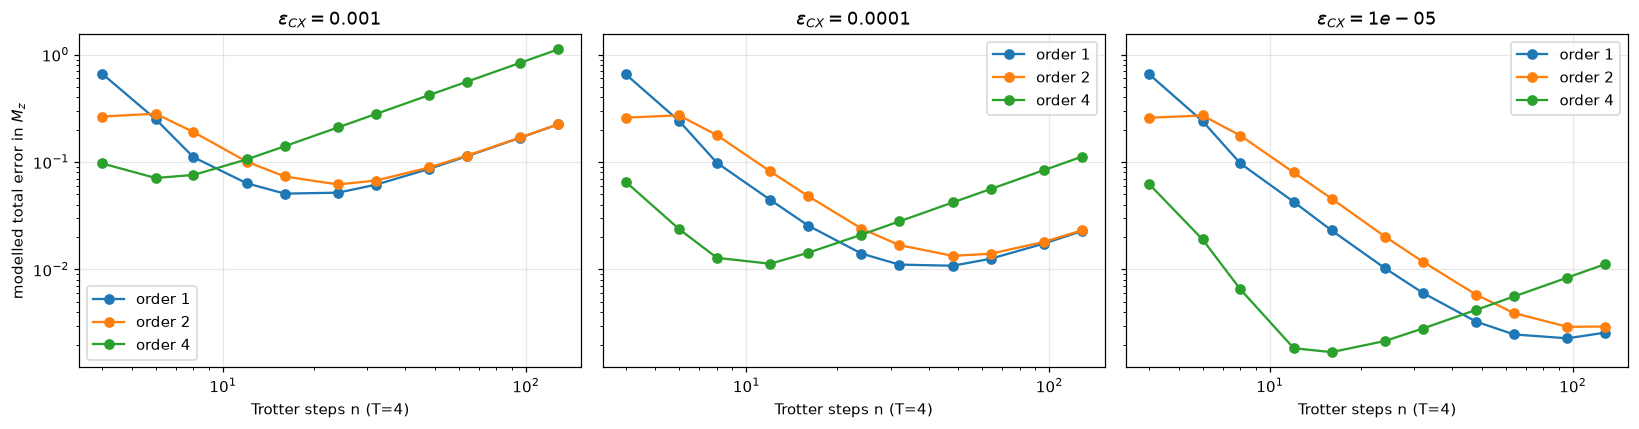

best steps                 model error                    
eps_CX    0.00001 0.00010 0.00100     0.00001   0.00010   0.00100
order                                                            
1            96.0    48.0    16.0    0.002286  0.010826  0.050808
2            96.0    48.0    24.0    0.002926  0.013389  0.061815
4            16.0    12.0     6.0    0.001700  0.011298  0.071007

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
summary = []
for ax, eps in zip(axes, [1e-3, 1e-4, 1e-5]):
    for order, color in zip(orders, ["C0", "C1", "C2"]):
        s = scan[scan.order == order].copy()
        s["total"] = s.obs_err + eps * s.cx / N_s
        ax.loglog(s.steps, s.total, "o-", color=color, label=f"order {order}")
        best = s.loc[s.total.idxmin()]
        summary.append({"eps_CX": eps, "order": order, "best steps": int(best.steps),
                        "CX": int(best.cx), "model error": best.total})
    ax.set(title=rf"$\varepsilon_{{CX}}={eps:g}$", xlabel="Trotter steps n (T=4)"); ax.legend()
axes[0].set_ylabel("modelled total error in $M_z$")
plt.tight_layout(); plt.show()
display(pd.DataFrame(summary).pivot(index="order", columns="eps_CX", values=["best steps", "model error"]))

**Answer to the "accuracy vs depth" and "higher order" questions.** With today's error rates (around $10^{-3}$ per CNOT), shorter circuits win: 16–24 steps of 1st or 2nd order, or just 6 steps of 4th order. The leftover error (about 5%) is mostly from noise, so adding more steps only makes things worse. With better hardware ($10^{-5}$), more steps pay off and 4th order becomes the best choice. So higher order only saves gates when you need high accuracy or the hardware is very good. This model is simple and ignores things like crosstalk, and error mitigation could push the best depth higher.

## 3. Intermediate track: SQD
### 3.1 How SQD works <a id="sqd"></a>

1. Prepare some state with a circuit and measure it many times. Each measurement gives a bitstring.
2. Keep the distinct bitstrings. They define a small set of basis states.
3. Build the Hamiltonian restricted to just those states and diagonalize it on a normal computer. The lowest eigenvalue is an estimate of the ground state energy, and it can never be below the true value.

So SQD only cares about **which** bitstrings show up, not the amplitudes or phases of the state. A good starting state is one whose samples hit the configurations that matter most for the ground state, without wasting shots on lots of useless ones.

I use `project_operator_to_subspace` from `qiskit-addon-sqd` to build the restricted Hamiltonian, and `StatevectorSampler` with a fixed seed for sampling. I use 16 spins, so there are 65,536 possible bitstrings and the samples only cover a small part of them.

In [16]:
N = 16
FULL = (1 << N) - 1
SHOTS = 2000

def exact_ground_state(H):
    vals, vecs = eigsh(H.to_matrix(sparse=True).real, k=1, which="SA")
    return float(vals[0]), vecs[:, 0]

def to_bool_matrix(ints):
    ints = np.asarray(ints, dtype=np.int64)
    return ((ints[:, None] >> np.arange(N - 1, -1, -1)) & 1).astype(bool)   # rightmost column is qubit 0

def sqd_energy(configs, H):
    configs = np.unique(np.asarray(configs, dtype=np.int64))
    Hp = project_operator_to_subspace(to_bool_matrix(configs), H)
    if len(configs) <= 400:
        return float(np.linalg.eigvalsh(Hp.toarray())[0]), len(configs)
    return float(eigsh(Hp, k=1, which="SA")[0][0]), len(configs)

def sample_circuit(qc, shots=SHOTS, seed=SEED):
    meas = qc.copy(); meas.measure_all()
    counts = StatevectorSampler(seed=seed).run([meas], shots=shots).result()[0].data.meas.get_int_counts()
    return np.repeat(np.fromiter(counts.keys(), dtype=np.int64), np.fromiter(counts.values(), dtype=np.int64))

def sample_state(vec, shots=SHOTS, seed=SEED):
    p = np.abs(vec) ** 2
    return np.random.default_rng(seed).choice(len(p), size=shots, p=p / p.sum())

def z2_complete(configs):
    # Flipping every spin is a symmetry, so the ground state has the same weight on x and its flipped version
    c = np.unique(configs)
    return np.unique(np.concatenate([c, c ^ FULL]))

# Sanity check: compare the addon's projection with a hand-written version
def tfim_subspace_matrix(configs, J, h):
    c = np.unique(configs); d = len(c); pos = {int(x): k for k, x in enumerate(c)}
    Hm = np.zeros((d, d))
    for k, x in enumerate(c):
        z = 1 - 2 * ((int(x) >> np.arange(N)) & 1)
        Hm[k, k] = -J * np.sum(z[:-1] * z[1:])
        for q in range(N):
            m = pos.get(int(x) ^ (1 << q))
            if m is not None: Hm[k, m] = -h
    return Hm
test_cfg = np.random.default_rng(1).integers(0, 2 ** N, 60)
H_test = tfim_hamiltonian(N, 1.0, 0.7)
assert np.isclose(np.linalg.eigvalsh(tfim_subspace_matrix(test_cfg, 1.0, 0.7))[0], sqd_energy(test_cfg, H_test)[0])
print("SQD projection agrees with an independent hand-written TFIM matrix.")

SQD projection agrees with an independent hand-written TFIM matrix.


### The starting states I tried

| name | circuit | idea |
|---|---|---|
| **GHZ** (from notebook 1) | H + chain of CNOTs | $(|0..0\rangle+|1..1\rangle)/\sqrt2$, exact ground state when $h=0$ |
| $|0\cdots0\rangle$ | nothing | just all spins up |
| $|+\rangle^{\otimes N}$ | H on every qubit | exact ground state when $J=0$; gives totally random bitstrings |
| **mean-field** $R_y(\theta^\*)^{\otimes N}$ | one rotation on each qubit | best state with no entanglement (θ chosen to minimize the energy) |
| **HVA**, $p=1,2,3$ | $|+\rangle$, then $p$ rounds of RZZ and RX | layers that copy the Hamiltonian's structure, tuned with VQE |
| **adiabatic ramp** | $|+\rangle$, then slowly turn on the ZZ coupling | slowly move from an easy ground state to the real one |
| **Krylov** | mean-field state evolved for different times, all samples combined | time evolution creates new useful bitstrings |
| random circuit | random rotations + CNOTs, 3 layers | a control with no structure |
| exact ground state | — | reference: perfect sampling of the true ground state |

Every state gets the same **2,000 shots** (the Krylov one splits them over its 8 circuits).

In [17]:
def ghz(n):
    qc = QuantumCircuit(n); qc.h(0)
    for i in range(n - 1): qc.cx(i, i + 1)
    return qc

def plus_state(n):
    qc = QuantumCircuit(n); qc.h(range(n)); return qc

def ry_product(n, theta):
    qc = QuantumCircuit(n); qc.ry(theta, range(n)); return qc

def hva(n, params):
    qc = plus_state(n)
    for g, b in zip(params[0::2], params[1::2]):
        for start in (0, 1):
            for i in range(start, n - 1, 2): qc.rzz(g, i, i + 1)
        qc.rx(b, range(n))
    return qc

def adiabatic_ramp(n, J, h, T=6.0, steps=30):
    qc, dtt = plus_state(n), T / steps
    for k in range(steps):
        s = (k + 0.5) / steps
        zz_layer(qc, s * J * dtt); x_layer(qc, h * dtt)
    return qc

def random_hea(n, layers=3, seed=SEED):
    r = np.random.default_rng(seed); qc = QuantumCircuit(n)
    for _ in range(layers):
        for i in range(n): qc.ry(r.uniform(0, 2 * np.pi), i)
        for i in range(n - 1): qc.cx(i, i + 1)
    return qc

# Fast NumPy version of the HVA, only used to speed up the VQE optimization.
# RZZ layers are just phases, and an RX layer is H-gates, phases, H-gates again,
# so each energy takes about a millisecond instead of building a whole circuit.
_idx = np.arange(2 ** N)
_z = 1 - 2 * ((_idx[None, :] >> np.arange(N)[:, None]) & 1)        # z value of qubit q in bitstring x
ZZ_SUM = np.sum(_z[:-1] * _z[1:], axis=0).astype(float)
Z_SUM = _z.sum(axis=0).astype(float)

def fwht(v):                                    # H gate on every qubit
    v = np.asarray(v)
    span = 1
    while span < v.size:
        w = v.reshape(-1, 2, span)
        v = np.stack([w[:, 0] + w[:, 1], w[:, 0] - w[:, 1]], axis=1).reshape(-1)
        span *= 2
    return v / np.sqrt(v.size)

def hva_state_fast(params):
    v = np.full(2 ** N, 2 ** (-N / 2), dtype=complex)
    for g, b in zip(params[0::2], params[1::2]):
        v = v * np.exp(-0.5j * g * ZZ_SUM)
        v = fwht(fwht(v) * np.exp(-0.5j * b * Z_SUM))
    return v

def tfim_energy_fast(v, J, h):
    return float(-J * np.abs(v) ** 2 @ ZZ_SUM - h * np.abs(fwht(v)) ** 2 @ Z_SUM)

def mean_field_energy(theta, J, h):          # for this state <Z> = cos(theta) and <X> = sin(theta)
    return -J * (N - 1) * np.cos(theta) ** 2 - h * N * np.sin(theta)

def energy(qc, H):
    return float(Statevector(qc).expectation_value(H).real)

def optimize_mean_field(J, h):
    res = minimize(lambda t: mean_field_energy(t[0], J, h), [0.6], method="L-BFGS-B", bounds=[(0, np.pi / 2)])
    return float(res.x[0])

def optimize_hva(J, h, p, warm=None, restarts=2, seed=SEED):
    r = np.random.default_rng(seed); best = None
    starts = ([np.concatenate([warm, [0.0, 0.0]])] if warm is not None else []) + \
             [r.uniform(-1, 1, 2 * p) for _ in range(restarts)]
    for x0 in starts:
        res = minimize(lambda x: tfim_energy_fast(hva_state_fast(x), J, h), x0, method="L-BFGS-B")
        if best is None or res.fun < best.fun: best = res
    return best.x

# Make sure the fast version agrees with Qiskit
_x = np.array([0.3, -0.7, 0.5, 0.2])
_H = tfim_hamiltonian(N, 1.0, 0.8)
assert np.allclose(hva_state_fast(_x), Statevector(hva(N, _x)).data, atol=1e-10)
assert np.isclose(tfim_energy_fast(hva_state_fast(_x), 1.0, 0.8), energy(hva(N, _x), _H))
assert np.isclose(mean_field_energy(0.4, 1.0, 0.8), energy(ry_product(N, 0.4), _H))
print("fast HVA simulator agrees with Qiskit Statevector")

def build_ansatze(J, h, verbose=True):
    t0 = time.time()
    H = tfim_hamiltonian(N, J, h)
    theta = optimize_mean_field(J, h)
    ans = {"GHZ": ghz(N), "|0...0>": QuantumCircuit(N), "|+>^N": plus_state(N),
           "mean-field Ry": ry_product(N, theta)}
    warm = None
    for p in (1, 2, 3):
        warm = optimize_hva(J, h, p, warm)
        ans[f"HVA p={p}"] = hva(N, warm)
    ans["adiabatic ramp"] = adiabatic_ramp(N, J, h)
    ans["random HEA"] = random_hea(N)
    if verbose:
        print(f"  ansätze for h={h} built in {time.time() - t0:.1f}s (mean-field theta*={theta:.3f})")
    return ans, theta

def krylov_samples(theta, J, h, K=8, dtk=0.25, shots=SHOTS, seed=SEED):
    per, out = shots // K, []
    for k in range(K):
        qc = trotter_circuit(N, dtk, k, order=2, J=J, h=h, initial=ry_product(N, theta))
        out.append(sample_circuit(qc, per, seed + k))
    return np.concatenate(out)

fast HVA simulator agrees with Qiskit Statevector


### 3.2 Starting point: GHZ <a id="ghz"></a>

In [18]:
_HS_CACHE = {}
def evaluate(name, samples, H, E0, psi0, state=None):
    key = id(H)
    if key not in _HS_CACHE:
        _HS_CACHE[key] = H.to_matrix(sparse=True)
    raw_e, raw_d = sqd_energy(samples, H)
    sym = z2_complete(samples)
    sym_e, sym_d = sqd_energy(sym, H)
    p0 = np.abs(psi0) ** 2
    return {"ansatz": name,
            "overlap |<psi0|phi>|^2": np.nan if state is None else abs(np.vdot(psi0, state)) ** 2,
            "<H> of ansatz": np.nan if state is None else float(np.real(np.vdot(state, _HS_CACHE[key] @ state))),
            "unique configs d": raw_d, "GS weight captured w": p0[np.unique(samples)].sum(),
            "SQD rel. error": (raw_e - E0) / abs(E0),
            "d (+Z2)": sym_d, "w (+Z2)": p0[sym].sum(), "SQD rel. error (+Z2)": (sym_e - E0) / abs(E0)}

J = 1.0
results_by_h, ansatz_cache = {}, {}
for h_val in (1.0,):
    H = tfim_hamiltonian(N, J, h_val); E0, psi0 = exact_ground_state(H)
    s = sample_circuit(ghz(N))
    display(pd.DataFrame([evaluate("GHZ", s, H, E0, psi0, Statevector(ghz(N)).data)]).set_index("ansatz"))
    print("E0 =", E0)

,overlap |<psi0|phi>|^2,<H> of ansatz,unique configs d,GS weight captured w,SQD rel. error,d (+Z2),w (+Z2),SQD rel. error (+Z2)
ansatz,,,,,,,,
GHZ,0.074994,-15.0,2,0.074994,0.250614,2,0.074994,0.250614


E0 = -20.016387900485142


GHZ only ever gives two bitstrings, all zeros and all ones, no matter how many shots you take. So SQD just solves a 2×2 problem and gets the classical ferromagnet energy, which is about 25% too high at the critical point. Extra shots don't help at all, so GHZ is a bad choice unless $h$ is small.

### 3.3 Comparing starting states at the critical point $J=h=1$ <a id="zoo"></a>

In [19]:
def run_zoo(J, h_val):
    H = tfim_hamiltonian(N, J, h_val); E0, psi0 = exact_ground_state(H)
    ans, theta = build_ansatze(J, h_val)
    rows = []
    for k, (name, qc) in enumerate(ans.items()):
        sv = Statevector(qc).data
        rows.append(evaluate(name, sample_circuit(qc, seed=SEED + 10 * k), H, E0, psi0, sv))
    rows.append(evaluate("Krylov (SKQD-style)", krylov_samples(theta, J, h_val), H, E0, psi0))
    rows.append(evaluate("exact GS (oracle)", sample_state(psi0), H, E0, psi0, psi0))
    return pd.DataFrame(rows).set_index("ansatz"), (H, E0, psi0, ans, theta)

t0 = time.time()
zoo_crit, ctx_crit = run_zoo(1.0, 1.0)
results_by_h[1.0], ansatz_cache[1.0] = zoo_crit, ctx_crit
print(f"done in {time.time() - t0:.1f}s; E0 = {ctx_crit[1]:.6f}")
display(zoo_crit.style.format(precision=4).background_gradient(subset=["SQD rel. error (+Z2)"], cmap="RdYlGn_r"))

  ansätze for h=1.0 built in 113.4s (mean-field theta*=0.563)
done in 170.2s; E0 = -20.016388


,overlap ||^2,of ansatz,unique configs d,GS weight captured w,SQD rel. error,d (+Z2),w (+Z2),SQD rel. error (+Z2)
ansatz,,,,,,,,
GHZ,0.0750,-15.0000,2,0.0750,0.2506,2,0.0750,0.2506
|0...0>,0.0375,-15.0000,1,0.0375,0.2506,2,0.0750,0.2506
|+>^N,0.2542,-16.0000,1968,0.0299,0.3505,3884,0.0596,0.3505
mean-field Ry,0.2291,-19.2667,356,0.1897,0.0630,712,0.3794,0.0630
HVA p=1,0.6241,-19.1302,1847,0.3200,0.1748,3476,0.4667,0.1391
HVA p=2,0.7832,-19.6606,1680,0.4368,0.1335,2970,0.5522,0.1101
HVA p=3,0.8546,-19.8092,1585,0.4707,0.1143,2780,0.5825,0.0891
adiabatic ramp,0.8950,-19.5885,1364,0.5032,0.0894,2352,0.5991,0.0767
random HEA,0.0000,-2.2402,1447,0.0188,0.3387,2560,0.0341,0.3278


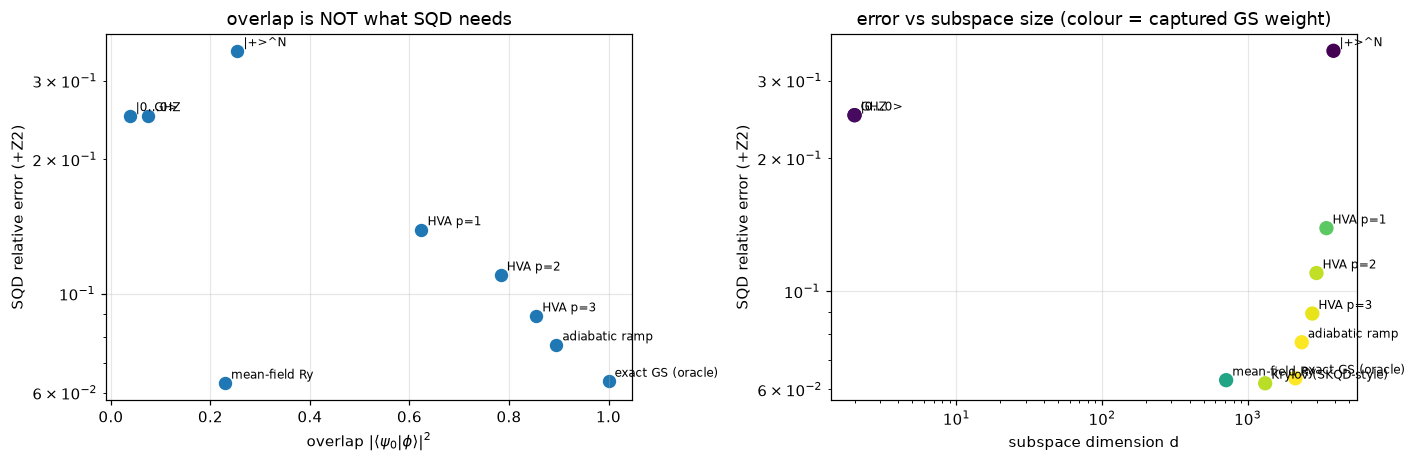

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
z = zoo_crit.drop(index=["random HEA"])
axes[0].scatter(z["overlap |<psi0|phi>|^2"], z["SQD rel. error (+Z2)"], s=60)
for name, r in z.iterrows():
    if not np.isnan(r["overlap |<psi0|phi>|^2"]):
        axes[0].annotate(name, (r["overlap |<psi0|phi>|^2"], r["SQD rel. error (+Z2)"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[0].set(xlabel=r"overlap $|\langle\psi_0|\phi\rangle|^2$", ylabel="SQD relative error (+Z2)", yscale="log",
            title="overlap is NOT what SQD needs")
axes[1].scatter(z["d (+Z2)"], z["SQD rel. error (+Z2)"], c=z["w (+Z2)"], cmap="viridis", s=70)
for name, r in z.iterrows():
    axes[1].annotate(name, (r["d (+Z2)"], r["SQD rel. error (+Z2)"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[1].set(xlabel="subspace dimension d", ylabel="SQD relative error (+Z2)", xscale="log", yscale="log",
            title="error vs subspace size (colour = captured GS weight)")
plt.tight_layout(); plt.show()

**What the comparison shows** ($h=J=1$, 2,000 shots, exact energy $E_0=-20.016$)

| | SQD error (+Z2) | bitstrings d |
|---|---|---|
| Krylov | **6.2%** | 1,320 |
| mean-field | **6.3%** | **712** |
| exact ground state | 6.4% | 2,128 |
| adiabatic ramp | 7.7% | 2,352 |
| HVA p=3 | 9.0% | 2,778 |
| GHZ | 25.1% | 2 |
| $|+\rangle^{\otimes N}$ / random | 33–35% | ~2,500–3,900 |

1. **Overlap with the ground state doesn't predict how well SQD does.** HVA p=3 has 85% overlap but loses to the mean-field state with only 23%. What matters is which bitstrings show up and how many are wasted.
2. **Fewer, better bitstrings win.** The mean-field state gives only 712 distinct bitstrings, almost all useful, and matches perfect ground-state sampling with a 3× smaller problem. Even perfect sampling only reaches about 6% here, because at the critical point the ground state is spread over a huge number of bitstrings.
3. **Time evolution helps.** The Krylov state gets the best energy, because evolving with $H$ naturally produces the bitstrings that $H$ connects. This is the idea behind SKQD, and it reuses the Trotter circuits from Part 2.
4. **Adding flipped copies is free.** The ground state is symmetric under flipping every spin, so for each bitstring I also add its flipped version ("+Z2"). It never hurts and sometimes helps a lot (HVA p=1: 17.5% → 13.9%).
5. **GHZ is a bad choice here,** since it only ever gives 2 bitstrings.

### 3.4 It depends on the phase <a id="phase"></a>

The model has three regimes: ferromagnetic ($h<J$), critical ($h=J$) and paramagnetic ($h>J$). I repeat the comparison at $h=0.5$ and $h=2$.

In [21]:
for h_val in (0.5, 2.0):
    t0 = time.time()
    results_by_h[h_val], ansatz_cache[h_val] = run_zoo(1.0, h_val)
    print(f"h={h_val}: done in {time.time() - t0:.1f}s")
phase_table = pd.DataFrame({f"h={h_val}": results_by_h[h_val]["SQD rel. error (+Z2)"] for h_val in sorted(results_by_h)})
phase_d = pd.DataFrame({f"h={h_val}": results_by_h[h_val]["d (+Z2)"] for h_val in sorted(results_by_h)})
display(phase_table.style.format("{:.2e}").background_gradient(cmap="RdYlGn_r", axis=None, low=0, high=0)
        .set_caption("SQD relative energy error (+Z2 completion), 2,000 shots"))
display(phase_d.style.set_caption("subspace dimension d (+Z2)"))

  ansätze for h=0.5 built in 74.2s (mean-field theta*=0.270)
h=0.5: done in 110.9s
  ansätze for h=2.0 built in 101.2s (mean-field theta*=1.571)
h=2.0: done in 139.9s


,h=0.5,h=1.0,h=2.0
ansatz,,,
GHZ,7.10e-02,2.51e-01,5.58e-01
|0...0>,7.10e-02,2.51e-01,5.58e-01
|+>^N,1.95e-01,3.51e-01,6.03e-01
mean-field Ry,1.21e-02,6.30e-02,5.90e-01
HVA p=1,1.75e-02,1.39e-01,4.04e-01
HVA p=2,1.62e-02,1.10e-01,4.03e-01
HVA p=3,1.03e-02,8.91e-02,3.44e-01
adiabatic ramp,1.11e-02,7.67e-02,3.98e-01
random HEA,1.87e-01,3.28e-01,4.89e-01


,h=0.5,h=1.0,h=2.0
ansatz,,,
GHZ,2,2,2
|0...0>,2,2,2
|+>^N,3884,3884,3884
mean-field Ry,144,712,3898
HVA p=1,3016,3476,3782
HVA p=2,1940,2970,3740
HVA p=3,1466,2780,3728
adiabatic ramp,756,2352,3770
random HEA,2560,2560,2560


**What changes with the phase**

* **Ferromagnet (h=0.5):** the ground state is close to GHZ, so most bitstrings are near all-zeros or all-ones. Every structured state gets around 1%. GHZ alone gets 7.1%, because it only has the two perfect configurations. Mean-field gets 1.2% with just 144 bitstrings, and Krylov gets 0.94% with 188, almost the same as perfect sampling (0.84%).
* **Critical point (h=1):** the hardest case. Mean-field, Krylov and perfect sampling all tie at about 6%.
* **Paramagnet (h=2):** in the Z basis everything fails (34–60%), even perfect sampling of the true ground state (36%). The ground state is close to $|+\cdots+\rangle$, which is spread evenly over all 65,536 bitstrings, so 2,000 shots can't capture it. The problem is the measurement basis, not the starting state. Section 3.5(c) fixes this.

**Bottom line:** no single starting state is best everywhere. It depends on the phase, and the GHZ state from notebook 1 is only good deep in the ferromagnetic phase.

### 3.5 A systematic way to choose the starting state <a id="systematic"></a>

From the results so far, here's a four-step approach.

**(a) Measure the right thing.** Compare starting states by how the error drops as you add shots (the quantum cost) and as the number of bitstrings grows (the classical cost), not by overlap or energy. I sweep the number of shots for the best candidates at $h=1$. For reference I also include the best possible set of $d$ bitstrings: the $d$ with the largest weight in the true ground state.

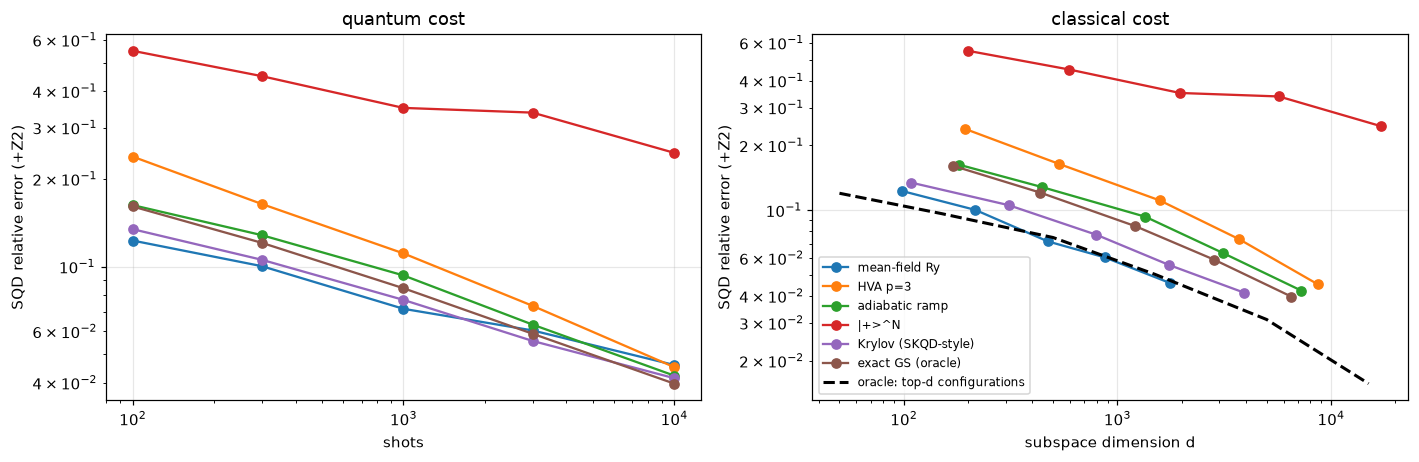

shots,100,300,1000,3000,10000
ansatz,,,,,
HVA p=3,0.238,0.164,0.111,0.073,0.045
Krylov (SKQD-style),0.134,0.106,0.077,0.056,0.041
adiabatic ramp,0.163,0.128,0.093,0.063,0.042
exact GS (oracle),0.161,0.121,0.084,0.059,0.040
mean-field Ry,0.123,0.100,0.072,0.060,0.046
|+>^N,0.550,0.450,0.351,0.338,0.246


shots,100,300,1000,3000,10000
ansatz,,,,,
HVA p=3,194,534,1580,3714,8694
Krylov (SKQD-style),108,310,798,1752,3912
adiabatic ramp,182,442,1350,3122,7276
exact GS (oracle),170,436,1214,2846,6524
mean-field Ry,98,216,472,872,1756
|+>^N,200,596,1964,5706,17134


oracle top-d: [(50, 0.1199), (150, 0.0965), (500, 0.0747), (1500, 0.0504), (5000, 0.0311), (15000, 0.0156)]


In [22]:
H1, E01, psi01, ans1, theta1 = ansatz_cache[1.0]
shot_grid = [100, 300, 1000, 3000, 10000]
curve_states = {"mean-field Ry": ans1["mean-field Ry"], "HVA p=3": ans1["HVA p=3"],
                "adiabatic ramp": ans1["adiabatic ramp"], "|+>^N": ans1["|+>^N"]}
curves = []
for name, qc in curve_states.items():
    for S in shot_grid:
        e, d = sqd_energy(z2_complete(sample_circuit(qc, S, SEED + S)), H1)
        curves.append({"ansatz": name, "shots": S, "d": d, "err": (e - E01) / abs(E01)})
for S in shot_grid:
    e, d = sqd_energy(z2_complete(krylov_samples(theta1, 1.0, 1.0, shots=S)), H1)
    curves.append({"ansatz": "Krylov (SKQD-style)", "shots": S, "d": d, "err": (e - E01) / abs(E01)})
    e, d = sqd_energy(z2_complete(sample_state(psi01, S, SEED + S)), H1)
    curves.append({"ansatz": "exact GS (oracle)", "shots": S, "d": d, "err": (e - E01) / abs(E01)})
curves = pd.DataFrame(curves)
order_p0 = np.argsort(-np.abs(psi01) ** 2)
oracle_topd = [(d, (sqd_energy(order_p0[:d], H1)[0] - E01) / abs(E01)) for d in [50, 150, 500, 1500, 5000, 15000]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for name, s in curves.groupby("ansatz", sort=False):
    axes[0].loglog(s.shots, s.err, "o-", label=name)
    axes[1].loglog(s.d, s.err, "o-", label=name)
axes[1].loglog(*zip(*oracle_topd), "k--", lw=2, label="oracle: top-d configurations")
axes[0].set(xlabel="shots", ylabel="SQD relative error (+Z2)", title="quantum cost")
axes[1].set(xlabel="subspace dimension d", ylabel="SQD relative error (+Z2)", title="classical cost")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
display(curves.pivot(index="ansatz", columns="shots", values="err").style.format("{:.3f}")
        .set_caption("SQD relative error (+Z2) vs shots"))
display(curves.pivot(index="ansatz", columns="shots", values="d").style.set_caption("subspace dimension d vs shots"))
print("oracle top-d:", [(d, round(e, 4)) for d, e in oracle_topd])

**What I found.** Error drops steadily with more shots for all the structured states. For a given problem size, the **mean-field state is the most efficient**: at 10,000 shots it gets 4.6% error with 1,756 bitstrings. That's slightly better than taking the 1,500 highest-weight bitstrings of the true ground state (5.0%). So the bitstrings with the biggest weight aren't automatically the most useful. You also need the ones that the Hamiltonian connects together. The uniform $|+\rangle^{\otimes N}$ state wastes its shots (17,134 bitstrings and still 25% error). Mean-field levels off sooner, so with big budgets Krylov and the adiabatic ramp catch up.

**(b) Tune the starting state for SQD, not for energy.** For a family of states, try different parameter values and check the SQD error for each. For the mean-field state $R_y(\theta)^{\otimes N}$, the angle that gives the lowest energy isn't the one that gives the best SQD result.

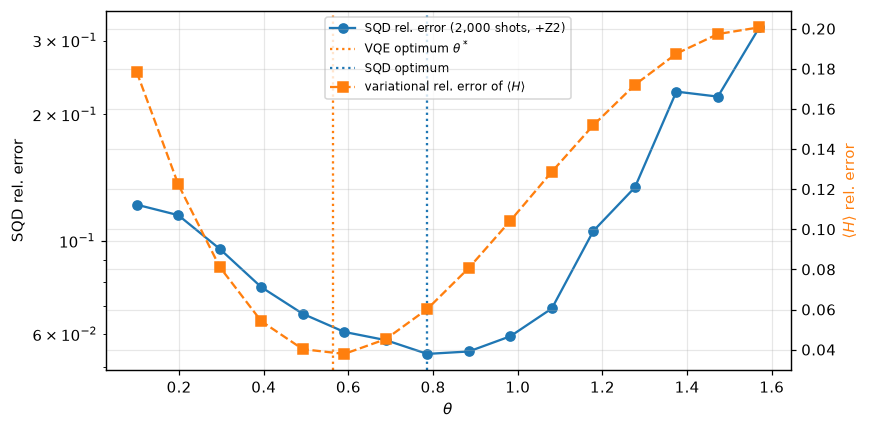

VQE optimum theta*=0.563; SQD-optimal theta=0.786 (SQD error 5.38e-02 with d=1658)


In [23]:
thetas = np.linspace(0.1, np.pi / 2, 16)
scan_rows = []
for th in thetas:
    qc = ry_product(N, th)
    e, d = sqd_energy(z2_complete(sample_circuit(qc, SHOTS, SEED + 7)), H1)
    scan_rows.append({"theta": th, "<H>": mean_field_energy(th, 1.0, 1.0), "SQD err": (e - E01) / abs(E01), "d": d})
scan_th = pd.DataFrame(scan_rows)
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(scan_th.theta, scan_th["SQD err"], "o-", label="SQD rel. error (2,000 shots, +Z2)")
ax2 = ax.twinx(); ax2.plot(scan_th.theta, (scan_th["<H>"] - E01) / abs(E01), "s--", color="C1", label=r"variational rel. error of $\langle H\rangle$")
ax.axvline(theta1, color="C1", ls=":", label=r"VQE optimum $\theta^*$")
best_th = scan_th.loc[scan_th["SQD err"].idxmin()]
ax.axvline(best_th.theta, color="C0", ls=":", label="SQD optimum")
ax.set_xlabel(r"$\theta$"); ax.set_ylabel("SQD rel. error"); ax2.set_ylabel(r"$\langle H\rangle$ rel. error", color="C1")
h1_, l1_ = ax.get_legend_handles_labels(); h2_, l2_ = ax2.get_legend_handles_labels()
ax.legend(h1_ + h2_, l1_ + l2_, fontsize=8, loc="upper center"); plt.tight_layout(); plt.show()
print(f"VQE optimum theta*={theta1:.3f}; SQD-optimal theta={best_th.theta:.3f} "
      f"(SQD error {best_th['SQD err']:.2e} with d={int(best_th.d)})")

**(c) Pick the measurement basis.** SQD works when the ground state is concentrated on a few bitstrings in whatever basis you measure. In the paramagnet, the ground state is spread out in the Z basis but concentrated in the X basis. To measure in the X basis, add an H gate on every qubit before measuring and swap X and Z in the Hamiltonian. You can choose the basis from whether $h$ is bigger than $J$, or by doing a small test run and seeing which basis gives fewer distinct bitstrings.

In [24]:
def hadamard_rotate(op):
    swap = str.maketrans({"X": "Z", "Z": "X"})
    return SparsePauliOp([lbl.translate(swap) for lbl in op.paulis.to_labels()], op.coeffs)

def x_basis(qc):
    out = qc.copy(); out.h(range(out.num_qubits)); return out

basis_rows = []
for h_val in sorted(ansatz_cache):
    H, E0, psi0, ans, theta = ansatz_cache[h_val]
    HX = hadamard_rotate(H)
    psi0X = Statevector(psi0).evolve(plus_state(N)).data   # ground state in the X basis
    for name in ["mean-field Ry", "HVA p=3", "adiabatic ramp"]:
        sZ = z2_complete(sample_circuit(ans[name], seed=SEED + 3))
        sX = sample_circuit(x_basis(ans[name]), seed=SEED + 3)
        # no flipped copies needed in the X basis
        eZ, dZ = sqd_energy(sZ, H)
        eX, dX = sqd_energy(sX, HX)
        basis_rows.append({"h": h_val, "ansatz": name, "Z basis err": (eZ - E0) / abs(E0), "Z basis d": dZ,
                           "X basis err": (eX - E0) / abs(E0), "X basis d": dX})
basis_df = pd.DataFrame(basis_rows).set_index(["h", "ansatz"])
display(basis_df.style.format({"Z basis err": "{:.2e}", "X basis err": "{:.2e}"}))

**What I found.** The basis makes a huge difference. At **h=2**, switching to the X basis brings the error from 37–60% down to **0.56–0.61%**, with only about 80 bitstrings. The mean-field state turns into just one bitstring, $|+\cdots+\rangle$, and still gets 5.6%. At **h=0.5** the Z basis is much better, as expected. At the critical point, HVA and the adiabatic ramp do better in the X basis (3.1–3.5% with under 500 bitstrings), but mean-field doesn't. So the best basis depends on both the state and the phase, and a quick test run can tell you which to use.

**(d) Improve the bitstrings afterwards.** You can make the set of bitstrings better on a normal computer by adding the ones the Hamiltonian connects to the important ones. I repeat this a few times: solve, keep the most important bitstrings, add every version of them with one spin flipped, and solve again. This works for any starting state. I cap the problem at 3,000 bitstrings (4.6% of all of them) so the comparison is fair.

In [25]:
def sqd_solve(configs, H):
    configs = np.unique(np.asarray(configs, dtype=np.int64))
    Hp = project_operator_to_subspace(to_bool_matrix(configs), H)
    if len(configs) <= 400:
        w, v = np.linalg.eigh(Hp.toarray()); return w[0], v[:, 0], configs
    w, v = eigsh(Hp, k=1, which="SA"); return w[0], v[:, 0], configs

def iterative_expansion(samples, H, d_max=3000, iterations=4):
    configs = z2_complete(samples)
    history = []
    for it in range(iterations + 1):
        e, vec, configs = sqd_solve(configs, H)
        history.append((len(configs), e))
        if it == iterations: break
        keep = configs[np.argsort(-np.abs(vec))[: d_max // (N + 1)]]          # most important bitstrings
        neighbours = np.concatenate([keep] + [keep ^ (1 << q) for q in range(N)])
        merged = z2_complete(np.concatenate([configs, neighbours]))
        if len(merged) > d_max:                                                 # keep only the most important ones
            e2, v2, c2 = sqd_solve(merged, H)
            merged = z2_complete(c2[np.argsort(-np.abs(v2))[: d_max // 2]])
        configs = merged
    return history

exp_rows = []
for h_val in sorted(ansatz_cache):
    H, E0, psi0, ans, theta = ansatz_cache[h_val]
    for name in ["GHZ", "mean-field Ry", "HVA p=3"]:
        hist = iterative_expansion(sample_circuit(ans[name], seed=SEED + 5), H)
        exp_rows.append({"h": h_val, "start": name, "initial err": (hist[0][1] - E0) / abs(E0),
                         "initial d": hist[0][0], "final err": (hist[-1][1] - E0) / abs(E0), "final d": hist[-1][0]})
exp_df = pd.DataFrame(exp_rows).set_index(["h", "start"])
display(exp_df.style.format({"initial err": "{:.2e}", "final err": "{:.2e}"}))

**What I found.** This is the biggest improvement you can make without the quantum computer. In the ferromagnet, every starting state ends up at about 0.05% error with roughly 1,500–1,700 bitstrings, even GHZ, which started with only 2. At the critical point they all end up around 3.6–4% with about 2,000 bitstrings. In the paramagnet, the Z basis gets stuck around 19%, which again shows you need to pick the right basis first (c) and then expand (d). The final error barely depends on where you started; the starting state mostly changes how quickly you get there.

### 3.6 What about noise? <a id="noise"></a>

On real hardware, noise adds random wrong bitstrings. SQD still can't go below the true energy, because extra bitstrings can only lower the estimate or leave it the same, never push it past the true value. Noise mostly just wastes some shots. To check, I sample the HVA p=2 state at $h=1$ with a noisy Aer simulation (0.1% error on 1-qubit gates, 1% on CNOTs, 2% on readout).

In [26]:
try:
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["sx", "x", "rz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cx"])
    nm.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))
    sim = AerSimulator(noise_model=nm, seed_simulator=SEED)
    qc = ans1["HVA p=2"].copy(); qc.measure_all()
    tqc = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    counts = sim.run(tqc, shots=SHOTS).result().get_counts()
    noisy = np.repeat([int(b, 2) for b in counts], list(counts.values()))
    clean = sample_circuit(ans1["HVA p=2"], seed=SEED + 30)
    rows = []
    for label, s in [("noiseless", clean), ("noisy (Aer)", noisy)]:
        e, d = sqd_energy(z2_complete(s), H1)
        rows.append({"sampling": label, "d": d, "GS weight w": (np.abs(psi01) ** 2)[z2_complete(s)].sum(),
                     "SQD rel. error": (e - E01) / abs(E01), "above E0?": e >= E01 - 1e-9})
    display(pd.DataFrame(rows).set_index("sampling"))
    print("2q gates in transpiled circuit:", tqc.count_ops().get("cx", 0))
except ImportError:
    print("qiskit-aer not installed: skipping the noisy-sampling check.")

,d,GS weight w,SQD rel. error,above E0?
sampling,,,,
noiseless,3018,0.549381,0.110438,True
noisy (Aer),3340,0.525037,0.101006,True


2q gates in transpiled circuit: 60


## 4. Conclusions <a id="conclusions"></a>

### Beginner track
| question | what I found |
|---|---|
| Template | Its "Trotter" curve was actually exact, because `PauliEvolutionGate` gets simulated as an exact matrix. You have to simulate the decomposed gates. |
| Correlations | Connected correlations spread inside a light cone. The measured speed goes from 2.9 to 3.6 as the threshold gets lower, approaching the predicted 4, and the signal roughly halves with each site of distance. |
| Step size | State error goes like $\Delta t^{1}$, $\Delta t^{2}$, $\Delta t^{4}$ (measured 1.1, 2.0, 4.0). For 1% error in $M_z$ up to $t=4$: $\Delta t\approx0.17$ (1st order), 0.08 (2nd order), 0.5 (4th order). |
| Hidden structure | Starting from $|0\cdots0\rangle$, 1st-order Trotter is exactly a 2nd-order formula for anything measured in the Z basis, so its $M_z$ error goes like $\Delta t^2$. |
| Accuracy vs depth | 2nd order costs the same as 1st if you split the X layer (Qiskit's default doubles the cost). For high accuracy, 4th order needs the fewest CNOTs. With realistic noise ($10^{-3}$ per CNOT), shorter circuits are better. |

### Intermediate track (SQD)
* **Is there a better starting state than GHZ?** Yes, everywhere except deep in the ferromagnetic phase. At the critical point the mean-field state (just one rotation per qubit, no CNOTs) and the Krylov state get about 6%, compared with 25% for GHZ. With the right basis and the expansion step, the error drops well below 1% where the ground state is concentrated.
* **A systematic way to choose:**
  1. Compare states by error vs shots and vs number of bitstrings, not by overlap or energy.
  2. Measure in the basis where the ground state is concentrated: Z when $h<J$, X when $h>J$. A small test run can decide.
  3. Use simple, shallow families of states (single rotations, HVA, adiabatic ramps, short time evolution), and tune them for SQD rather than for energy. The best angle was 0.79 for SQD vs 0.56 for energy.
  4. Add the flipped copies and expand to neighbouring bitstrings. This took GHZ from 7.1% to 0.056% at $h=0.5$ with about 1,500 bitstrings.
  5. Use time evolution (Krylov / SKQD) to generate useful bitstrings. It reuses the Trotter circuits from Part 2, and IBM uses this approach on large problems.
* **Noise:** SQD stayed above the true energy, and the noisy samples didn't make the result worse in my test.

### Limitations
This is a 16-spin study on simulators, mostly without noise, with one random seed per setting. Close results (like 6.2% vs 6.3%) could swap with a different seed. The 1D Ising model can be solved exactly on a normal computer, so SQD has no real advantage here. The point was to learn how to pick and test starting states before trying harder problems.

### Credits
Original notebook by **B. Tirado**, *Simulating Quantum Dynamics: The Transverse-Field Ising Model*, BasQ Qiskit Fall Fest 2026 (text CC BY 4.0, code Apache 2.0), with additions by **M. Gutiérrez** (UCR, EnLuz Qiskit Fall Fest 2026). This solution builds on that material under the same licences.